# 02 — Linear Regression with scikit-learn

**Overview:** fit the same synthetic multiple-regression data from `01_linear_regression_numpy.ipynb`
using `sklearn.linear_model.LinearRegression`, confirm it matches the from-scratch closed-form
solution, and compute MSE/MAE/RMSE/R² with `sklearn.metrics` on a proper train/test split.

**Required libraries:** `numpy`, `scikit-learn`, `matplotlib`.

Connects to: `01_linear_regression_numpy.ipynb`. Leads to: `08_classification` (the classification
analog of everything here).

### Abbreviations used in this notebook

| Term | Full form | What it is |
|---|---|---|
| **MSE** | Mean Squared Error | Average of squared prediction errors; the standard regression loss. |
| **MAE** | Mean Absolute Error | Average of absolute errors; less outlier-sensitive than MSE. |
| **RMSE** | Root Mean Squared Error | Square root of MSE; in the same units as the target. |
| **R²** | Coefficient of determination | Fraction of target variance explained by the model (1 = perfect). |
| **F1** | F1 score | Harmonic mean of precision and recall. |

## 0. Environment & data (same generating process as the from-scratch notebook)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

rng = np.random.default_rng(42)
n = 200
X = rng.uniform(-5, 5, size=(n, 2))
true_w = np.array([3.0, -2.0])
true_b = 5.0
y = X @ true_w + true_b + rng.normal(scale=1.0, size=n)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("train:", X_train.shape, "test:", X_test.shape)


train: (160, 2) test: (40, 2)


## 1. Fit with scikit-learn and compare to the from-scratch closed-form solution

In [2]:
model = LinearRegression().fit(X_train, y_train)
print("sklearn learned coef_:", model.coef_.round(3), "(true:", true_w, ")")
print("sklearn learned intercept_:", round(model.intercept_, 3), "(true:", true_b, ")")

# Recompute the closed-form solution on the SAME training split for a fair comparison.
X_train_bias = np.column_stack([X_train, np.ones(len(X_train))])
w_closed_form = np.linalg.inv(X_train_bias.T @ X_train_bias) @ X_train_bias.T @ y_train
w_cf, b_cf = w_closed_form[:-1], w_closed_form[-1]

print("\nclosed-form (manual) coef:", w_cf.round(3))
print("closed-form (manual) intercept:", round(b_cf, 3))

assert np.allclose(model.coef_, w_cf, atol=1e-6)
assert abs(model.intercept_ - b_cf) < 1e-6
print("\nsklearn's solver matches the manual closed-form solution to floating-point precision.")


sklearn learned coef_: [ 3.043 -2.03 ] (true: [ 3. -2.] )
sklearn learned intercept_: 4.905 (true: 5.0 )

closed-form (manual) coef: [ 3.043 -2.03 ]
closed-form (manual) intercept: 4.905

sklearn's solver matches the manual closed-form solution to floating-point precision.


## 2. Evaluate on the held-out test set with sklearn.metrics

🎯 **Interview Tip:** always evaluate on data the model never trained on — training-set metrics
tell you almost nothing about generalization (see `06_ml_fundamentals` and `11_generalization`).

In [3]:
y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Test MSE:  {mse:.4f}")
print(f"Test MAE:  {mae:.4f}")
print(f"Test RMSE: {rmse:.4f}")
print(f"Test R²:   {r2:.4f}")

assert r2 > 0.8   # the data was generated from a clean linear process with modest noise


Test MSE:  1.0976
Test MAE:  0.8370
Test RMSE: 1.0477
Test R²:   0.9907


## 3. Residual analysis

💡 **Key Idea:** a good linear fit's residuals should look like random noise, with no visible pattern against predictions.

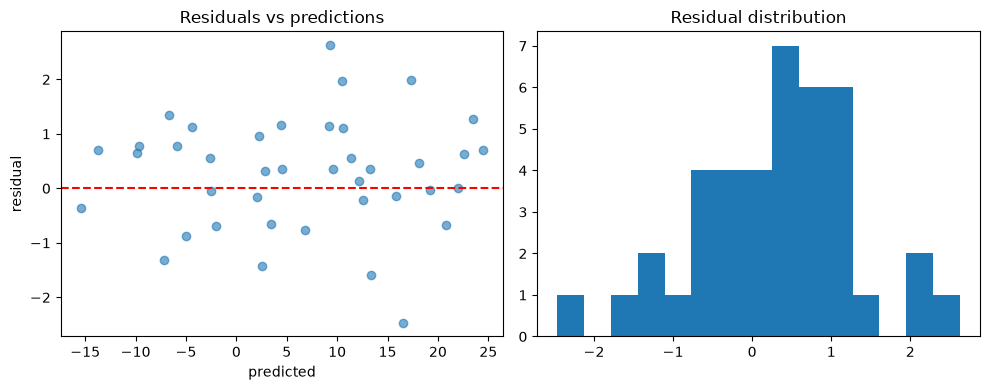

mean residual (should be close to 0): 0.2659


In [4]:
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(y_pred, residuals, alpha=0.6)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("predicted"); axes[0].set_ylabel("residual"); axes[0].set_title("Residuals vs predictions")

axes[1].hist(residuals, bins=15)
axes[1].set_title("Residual distribution")
plt.tight_layout(); plt.show()

print("mean residual (should be close to 0):", residuals.mean().round(4))
assert abs(residuals.mean()) < 0.5


## 4. Connection to what's next

The exact same fit → predict → evaluate pipeline, with the same train/test discipline, is
reused in `08_classification` — only the model and the metrics change (accuracy/precision/
recall/F1 instead of MSE/MAE/RMSE/R²).

## 5. Interview questions
1. Why evaluate on a held-out test set instead of the training set?
2. Why would sklearn's `LinearRegression` and a manual closed-form solve to the exact same weights?
3. What should a residual-vs-prediction plot look like for a good linear fit, and what would a curved pattern suggest?
4. Why is comparing RMSE across two different datasets potentially misleading?
5. What's the relationship between R² and the correlation coefficient for simple linear regression?

## 6. Exercises
1. Refit the model with only 1 of the 2 features and compare R² to the full model.
2. Introduce heteroscedastic noise (noise that grows with `|x|`) and see how the residual plot changes.
3. Compute a 95% prediction interval width using the residual standard deviation.

## 7. Summary

✅ scikit-learn's `LinearRegression` solves the same optimization problem as the from-scratch
normal equation; proper evaluation always happens on held-out data, and residual plots catch
model misspecification that a single R² number can hide. Next: `08_classification`.